# 04 · Property recommender

A buyer states constraints (budget, property type, location, bedrooms, size), and the recommender
returns the listings that meet them, **best value first**.

**How it works**

1. **Hard rules (filtering):** keep only listings that satisfy every constraint in the buyer
   profile.
2. **Fair price:** every listing gets a fair-price estimate from the random forest (notebook 03),
   using **out-of-fold** predictions. The data is split into 5 folds, and each listing is priced by
   a model trained on the other 4, so no listing is ever judged by a model that saw it.
3. **Two value signals:**
   * *value gap* = (fair price − asking price) / fair price, the model's view
   * *price-per-m² discount*: how far the listing's price per m² is below the median for the same
     source, district and type, a simple market comparison
4. **Ranking:** the *value score* is the average of the two signals, so a listing ranks high only
   when the model **and** the market comparison agree that it is cheap. A single signal would
   simply reward the listings with the most broken prices.
5. **Sanity rule:** listings more than 35% below their fair price, or priced at less than half the
   segment median per m², are flagged as likely data errors and excluded. Typical causes are a down
   payment entered as the price or a wrong area.
6. **Explanation:** each recommendation states both signals in plain words.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from egypt_real_estate import modeling, plotting
from egypt_real_estate.cleaning import load_clean
from egypt_real_estate.recommender import BuyerProfile, PropertyRecommender

plotting.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.0f}")
pd.set_option("display.max_colwidth", 90)

listings = load_clean()

In [2]:
model = modeling.build_models()["Random forest"]
fair_price = modeling.out_of_fold_predictions(model, listings)
recommender = PropertyRecommender(listings, fair_price)

oof = modeling.regression_metrics(listings["price"], fair_price)
print(f"Out-of-fold fair-price accuracy: median error {oof['Median APE (%)']:.1f}%, "
      f"{oof['Within 20% (%)']:.0f}% of listings within ±20%")

Out-of-fold fair-price accuracy: median error 22.3%, 46% of listings within ±20%


Within ±20% of fair price: 45%
Flagged as suspicious and excluded from recommendations: 17.0%


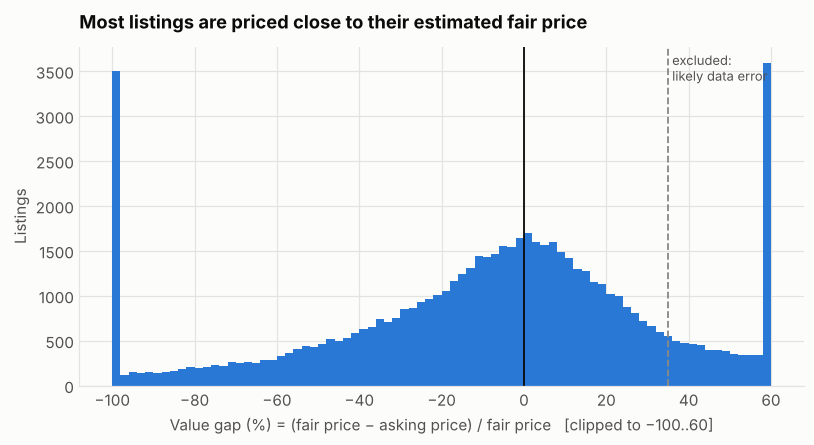

In [3]:
gap = recommender.listings["value_gap_pct"]
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.hist(gap.clip(-100, 60), bins=80, color=plotting.PRIMARY)
ax.axvline(0, color=plotting.TEXT, linewidth=1.2)
ax.axvline(35, color=plotting.MUTED, linewidth=1.2, linestyle="--")
ax.text(36, ax.get_ylim()[1] * 0.9, "excluded:\nlikely data error", fontsize=8.5, color=plotting.TEXT_SECONDARY)
ax.set_xlabel("Value gap (%) = (fair price − asking price) / fair price   [clipped to −100..60]")
ax.set_ylabel("Listings")
ax.set_title("Most listings are priced close to their estimated fair price")
plotting.save(fig, "value_gap_distribution")
plt.show()
print(f"Within ±20% of fair price: {gap.abs().le(20).mean():.0%}")
print(f"Flagged as suspicious and excluded from recommendations: {recommender.listings['suspicious'].mean():.1%}")

## Example 1: family apartment in New Cairo

3+ bedrooms, EGP 6–9M, current listings (Bayut).

In [4]:
family = BuyerProfile(min_budget=6e6, max_budget=9e6, property_type="Apartment",
                      district="New Cairo", min_bedrooms=3, source="Bayut")
print(f"{len(recommender.filter(family)):,} listings match the hard rules")
recommender.recommend(family, top_n=8)

1,305 listings match the hard rules


,type,district,compound,bedrooms,bathrooms,area_sqm,price,fair_price,value_score,source,why
43267,Apartment,New Cairo,NaN,3,2,250,7000000,"10,625,000",42,Bayut,34% below estimated fair price; price/m² 49% below the New Cairo apartment median
38344,Apartment,New Cairo,NaN,3,3,206,6000000,"8,897,000",40,Bayut,33% below estimated fair price; price/m² 47% below the New Cairo apartment median
47897,Apartment,New Cairo,Mountain View Icity,3,3,235,6800000,"9,948,000",40,Bayut,32% below estimated fair price; price/m² 48% below the New Cairo apartment median
37111,Apartment,New Cairo,Mountain View Icity,3,3,220,6600000,"9,754,000",39,Bayut,32% below estimated fair price; price/m² 46% below the New Cairo apartment median
25821,Apartment,New Cairo,NaN,3,3,228,6840000,"9,895,000",38,Bayut,31% below estimated fair price; price/m² 46% below the New Cairo apartment median
31270,Apartment,New Cairo,NaN,4,4,210,6600000,"9,779,000",38,Bayut,33% below estimated fair price; price/m² 43% below the New Cairo apartment median
47676,Apartment,New Cairo,NaN,4,3,225,7000000,"10,164,000",37,Bayut,31% below estimated fair price; price/m² 44% below the New Cairo apartment median
38906,Apartment,New Cairo,El Yasmeen 2,3,2,210,6500000,"9,355,000",37,Bayut,31% below estimated fair price; price/m² 44% below the New Cairo apartment median


## Example 2: standalone home in West Cairo

Villa, townhouse or twin house in Sheikh Zayed or 6th of October, up to EGP 25M, at least 250 m².

In [5]:
west_cairo_home = BuyerProfile(max_budget=25e6, property_type=["Villa", "Townhouse", "Twin House"],
                               district=["Sheikh Zayed", "6th of October"], min_area_sqm=250,
                               source="Bayut")
print(f"{len(recommender.filter(west_cairo_home)):,} listings match the hard rules")
recommender.recommend(west_cairo_home, top_n=8)

1,293 listings match the hard rules


,type,district,compound,bedrooms,bathrooms,area_sqm,price,fair_price,value_score,source,why
40758,Villa,6th of October,Nyoum October,4,3,261,7500000,"11,224,000",42,Bayut,33% below estimated fair price; price/m² 50% below the 6th of October villa median
42613,Villa,Sheikh Zayed,Zayard,5,4,300,9000000,"13,515,000",41,Bayut,33% below estimated fair price; price/m² 48% below the Sheikh Zayed villa median
24874,Villa,6th of October,NaN,4,2,264,7590000,"10,957,000",40,Bayut,31% below estimated fair price; price/m² 50% below the 6th of October villa median
19147,Villa,6th of October,Badya Palm Hills,6,7,401,12150690,"18,089,000",40,Bayut,33% below estimated fair price; price/m² 47% below the 6th of October villa median
48053,Townhouse,Sheikh Zayed,Beverly Hills,4,4,310,10800000,"16,019,000",40,Bayut,33% below estimated fair price; price/m² 47% below the Sheikh Zayed townhouse median
45675,Villa,Sheikh Zayed,NaN,4,6,327,9500000,"13,480,000",40,Bayut,30% below estimated fair price; price/m² 50% below the Sheikh Zayed villa median
50608,Villa,6th of October,Al Solaimaneyah Golf City,3,3,650,19000000,"27,137,000",40,Bayut,30% below estimated fair price; price/m² 49% below the 6th of October villa median
39704,Villa,6th of October,O West,4,3,250,8000000,"12,271,000",40,Bayut,35% below estimated fair price; price/m² 44% below the 6th of October villa median


## Example 3: summer chalet on the North Coast

Chalet, 2+ bedrooms, up to EGP 12M.

In [6]:
summer = BuyerProfile(max_budget=12e6, property_type="Chalet", district="North Coast",
                      min_bedrooms=2, source="Bayut")
print(f"{len(recommender.filter(summer)):,} listings match the hard rules")
recommender.recommend(summer, top_n=8)

715 listings match the hard rules


,type,district,compound,bedrooms,bathrooms,area_sqm,price,fair_price,value_score,source,why
47819,Chalet,North Coast,NaN,2,2,100,4700000,"6,866,000",40,Bayut,32% below estimated fair price; price/m² 49% below the North Coast chalet median
48389,Chalet,North Coast,Plage,3,2,125,6000000,"8,715,000",39,Bayut,31% below estimated fair price; price/m² 48% below the North Coast chalet median
34833,Chalet,North Coast,Jefaira,3,4,160,7500000,"10,678,000",39,Bayut,30% below estimated fair price; price/m² 49% below the North Coast chalet median
32367,Chalet,North Coast,NaN,2,2,100,4600000,"6,368,000",39,Bayut,28% below estimated fair price; price/m² 50% below the North Coast chalet median
21293,Chalet,North Coast,Azha,2,2,139,6740000,"9,132,000",37,Bayut,26% below estimated fair price; price/m² 47% below the North Coast chalet median
34764,Chalet,North Coast,NaN,3,2,141,6500000,"8,365,000",36,Bayut,22% below estimated fair price; price/m² 50% below the North Coast chalet median
45002,Chalet,North Coast,Solare,2,2,155,7500000,"9,965,000",36,Bayut,25% below estimated fair price; price/m² 47% below the North Coast chalet median
40004,Chalet,North Coast,Amwaj,2,2,95,5000000,"7,056,000",36,Bayut,29% below estimated fair price; price/m² 43% below the North Coast chalet median


## Using it in your own code

```python
from egypt_real_estate.recommender import BuyerProfile, PropertyRecommender

profile = BuyerProfile(max_budget=5e6, property_type="Apartment", region="Greater Cairo", min_bedrooms=2)
recommender.recommend(profile, top_n=10)
```

`BuyerProfile` fields: `max_budget`, `min_budget`, `property_type` (one or a list), `district` (one or
a list), `region`, `min_bedrooms`, `min_area_sqm`, `source`.

## Notes and limits

* "Value" is relative to estimates: the fair price has a median error of about 22% (notebook 03).
  A high value score means "worth a closer look", not proof of a bargain.
* The fair price can't see finishing, floor, view or payment plan. A listing that looks cheap may
  be unfinished or off-plan with a long delivery date. Always check the listing itself.
* Filter by `source="Bayut"` for the current market. Older OLX and Cairo listings are useful for
  analysis but have probably been sold or repriced.